# Encoder–decoder: hiểu cơ chế và tự viết mạng neural nông

**Ba ví dụ chạy được:** autoencoder `4 → 2 → 4`, CBOW và Skip-gram bằng NumPy.

Notebook bám theo [slide NLP-1](slide/NLP-1.pdf): trang 10 chứa cả autoencoder và RNN encoder–decoder; trang 11–14 nói về CBOW và Skip-gram. Phần cơ chế là trọng tâm. Các mô hình lớn và ba đề tài NCKHSV được giải thích ở mức ý tưởng, không triển khai trong notebook này.

**Cách dùng:** mở bằng Jupyter hoặc VS Code, chọn Python kernel rồi **Restart Kernel → Run All**. Dữ liệu nằm hoàn toàn trong notebook; không tải model/dataset, không cần GPU hay API key. Các output lưu sẵn là kết quả chạy thực tế, có thể chạy lại để kiểm tra.

Nếu môi trường chưa có thư viện, chạy trong terminal:

```bash
python -m pip install numpy matplotlib nbformat nbclient ipykernel jupyterlab
```

Lộ trình: **1. Cơ chế** → **2. Autoencoder và backprop** → **3. CBOW** → **4. Skip-gram** → **5. Giới hạn, câu hỏi tự kiểm tra**. Mã có seed cố định; sai khác số học nhỏ có thể xuất hiện giữa phiên bản NumPy/BLAS.

## 1. Encoder–decoder thực sự làm việc như thế nào?

Encoder và decoder là **hai vai trò trong một mô hình**:

- **Encoder** biến đầu vào thành biểu diễn mà mô hình có thể dùng: vector ẩn, chuỗi vector hoặc bản đồ đặc trưng.
- **Decoder** sử dụng biểu diễn ấy để dự đoán đầu ra phù hợp nhiệm vụ: dữ liệu tái tạo, từ tiếp theo, ảnh phân đoạn…
- **Hàm mất mát** so sánh dự đoán với mục tiêu, tạo tín hiệu để cập nhật tham số **cả hai khối**.

Với mẫu vector và quy ước vector hàng:

$$z=f_\theta(x),\qquad \hat y=g_\phi(z),\qquad
\mathcal L(\theta,\phi)=\frac{1}{N}\sum_i\ell(g_\phi(f_\theta(x_i)),y_i).$$

`θ` là tham số encoder, `φ` là tham số decoder. Khi chưa học, chúng thường là các số ngẫu nhiên; biểu diễn chưa mang ý nghĩa hữu ích. Tối ưu loss khiến encoder giữ thông tin cần cho nhiệm vụ và decoder học cách sử dụng thông tin đó.

**Encode không phải mã hóa bảo mật.** Decoder học một ánh xạ, không nhất thiết là phép nghịch đảo toán học của encoder. Encoder cũng không phải lúc nào cũng giảm số chiều: attention giữ nhiều vector, còn embedding có thể tăng chiều so với một ID số nguyên.

| Trường hợp | Đầu vào | Mục tiêu | Biểu diễn | Đầu ra được học |
|---|---|---|---|---|
| Autoencoder | Vector/ảnh `x` | Chính `x` | Vector latent `z` | Khôi phục `x̂` |
| Denoising autoencoder | Bản nhiễu `x̃` | Bản sạch `x` | `z` | Khử nhiễu |
| CBOW | Các từ ngữ cảnh | Từ ở giữa | Trung bình embedding | Phân phối từ ở giữa |
| Skip-gram | Từ ở giữa | Các từ ngữ cảnh | Embedding từ giữa | Phân phối từ xung quanh |
| Seq2seq | Một chuỗi token | Chuỗi đích, có thể khác độ dài | Trạng thái encoder | Chuỗi được sinh từng bước |

CBOW/Skip-gram có thể được nhìn theo phép phân rã encode → predict/decode trong bài học, nhưng **không phải autoencoder và không phải mô hình seq2seq dịch cả câu**. Với Word2Vec, phần đầu ra thường gọi là output layer; sau huấn luyện ta thường giữ bảng embedding đầu vào để sử dụng tiếp.

In [1]:
import sys
import platform
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

SEED = 42
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "font.family": "DejaVu Sans", "font.size": 10})
print("Python:", platform.python_version())
print("NumPy:", np.__version__, "| Matplotlib:", matplotlib.__version__)
print("Thiết bị: CPU | Dữ liệu: tự sinh trong notebook | Seed:", SEED)

Python: 3.11.14
NumPy: 2.2.6 | Matplotlib: 3.10.8
Thiết bị: CPU | Dữ liệu: tự sinh trong notebook | Seed: 42


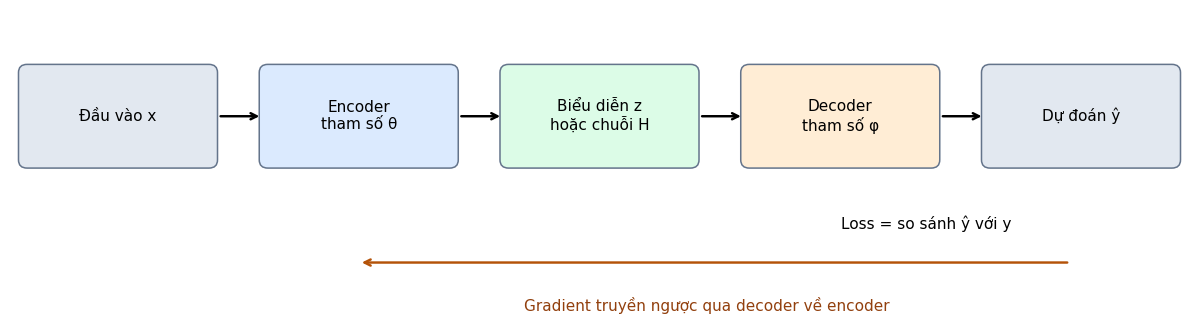

In [2]:
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(11, 3.1))
ax.set(xlim=(0, 11), ylim=(0, 3))
ax.axis("off")
boxes = [(0.15, "Đầu vào x", "#e2e8f0"),
         (2.4, "Encoder\ntham số θ", "#dbeafe"),
         (4.65, "Biểu diễn z\nhoặc chuỗi H", "#dcfce7"),
         (6.9, "Decoder\ntham số φ", "#ffedd5"),
         (9.15, "Dự đoán ŷ", "#e2e8f0")]
for x, label, color in boxes:
    ax.add_patch(FancyBboxPatch((x, 1.55), 1.7, 0.85,
                               boxstyle="round,pad=0.08", facecolor=color, edgecolor="#64748b"))
    ax.text(x + 0.85, 1.975, label, ha="center", va="center")
for x in [1.85, 4.1, 6.35, 8.6]:
    ax.annotate("", (x + 0.5, 1.975), (x + 0.08, 1.975),
                arrowprops={"arrowstyle": "->", "lw": 1.6})
ax.text(8.55, 0.88, "Loss = so sánh ŷ với y", ha="center")
ax.annotate("", (3.25, 0.55), (9.9, 0.55),
            arrowprops={"arrowstyle": "->", "color": "#b45309", "lw": 1.6})
ax.text(6.5, 0.08, "Gradient truyền ngược qua decoder về encoder", ha="center", color="#92400e")
plt.tight_layout()
plt.show()

### 1.1 Một vòng huấn luyện khác suy luận thế nào?

1. Lấy minibatch gồm đầu vào `X` và mục tiêu `Y`.
2. **Forward:** `X → encoder → Z → decoder → dự đoán`.
3. **Loss:** đo mức sai so với `Y`. Ví dụ dữ liệu liên tục dùng MSE; dự đoán token dùng cross-entropy.
4. **Backward:** dùng quy tắc dây chuyền để tính gradient của loss theo tham số. Với vector ẩn, tín hiệu từ decoder đi ngược qua `z` để thay đổi encoder.
5. **Update:** optimizer cập nhật tham số theo gradient. Lặp lại trên các batch/epoch.

Trong **suy luận**, giữ tham số cố định, chỉ chạy forward để dự đoán. Không cần mục tiêu thật. Không tính loss cũng không có nghĩa là mô hình chắc chắn đúng.

**Mạng nông** ở ba ví dụ dưới có một tầng biểu diễn ẩn và một tầng đầu ra. Số epoch không làm mạng trở nên “sâu”; độ sâu nói về các tầng biến đổi được xếp chồng.

### 1.2 Từ mạng vector đến encoder–decoder cho chuỗi

Ví dụ dịch minh họa bằng tay: `tôi yêu mèo → i love cats`. Đây là ví dụ giải thích, không phải kết quả của một mô hình dịch đã huấn luyện trong notebook.

Encoder RNN đọc lần lượt token và cập nhật:

$$h_t=\tanh(E[x_t]W_x+h_{t-1}W_h+b_h).$$

Trong seq2seq cơ bản, `c = h_T` truyền thông tin sang decoder. Decoder sử dụng trạng thái trước và token trước để tạo phân phối token tiếp theo. GRU/LSTM có cơ chế cập nhật khác; LSTM còn có cell state, không chỉ một hidden state. Ý tưởng đọc chuỗi rồi sinh chuỗi được trình bày trong [Sutskever và cộng sự, 2014](https://arxiv.org/abs/1409.3215).

| Bước | Decoder input khi teacher forcing | Token mục tiêu | Decoder input khi suy luận |
|---|---|---|---|
| 1 | `<BOS>` | `i` | `<BOS>` |
| 2 | `i` thật | `love` | Token mô hình vừa dự đoán ở bước 1 |
| 3 | `love` thật | `cats` | Token mô hình vừa dự đoán ở bước 2 |
| 4 | `cats` thật | `<EOS>` | Token mô hình vừa dự đoán ở bước 3 |

Loss khi huấn luyện:

$$\mathcal L=-\frac{1}{M}\sum_{i,t\,\mathrm{hợp\ lệ}}
\log P(y_{i,t}^{*}\mid y_{i,<t}^{*},x_i),$$

trong đó `M` là số token mục tiêu hợp lệ, không tính `<PAD>`. Decoder input là chuỗi đích **dịch phải một vị trí**. Nếu cho decoder nhìn trực tiếp token cần đoán thì bị rò rỉ đáp án. Teacher forcing dùng token đúng trước đó; khi suy luận, lỗi ở token trước có thể kéo theo lỗi ở token sau. Dừng ở `<EOS>` hoặc giới hạn độ dài; `argmax` từng bước là greedy decoding, không bảo đảm chuỗi có xác suất tổng thể lớn nhất.

### 1.3 Vì sao cần attention? Transformer có gì khác?

Nén cả một chuỗi dài vào một vector duy nhất có thể làm mất thông tin cần cho đầu ra. Attention cho decoder truy cập nhiều trạng thái encoder và tạo context riêng ở mỗi bước:

$$e_{t,i}=\mathrm{score}(s_{t-1},h_i),\qquad
\alpha_{t,i}=\frac{\exp(e_{t,i})}{\sum_j\exp(e_{t,j})},\qquad
c_t=\sum_i\alpha_{t,i}h_i.$$

`α` là trọng số tổng bằng 1 trên các vị trí hợp lệ. Nó được học thông qua nhiệm vụ; không phải nhãn giải thích tuyệt đối về suy nghĩ của mô hình. [Bahdanau và cộng sự](https://arxiv.org/abs/1409.0473) nghiên cứu việc học căn chỉnh và dịch bằng cơ chế này.

Trong [Transformer encoder–decoder gốc](https://arxiv.org/abs/1706.03762):

- Encoder dùng self-attention để tạo chuỗi biểu diễn `H`, cộng thông tin vị trí và các khối feed-forward/residual/normalization.
- Decoder dùng **masked self-attention** để không đọc token tương lai, rồi **cross-attention** để truy cập `H`.
- Teacher forcing cho phép xử lý các vị trí đích song song khi train với causal mask; lúc sinh tự hồi quy vẫn phải chờ token trước.
- Encoder và decoder không bắt buộc đối xứng về số tầng hoặc kích thước. Attention làm giảm khó khăn của cổ chai đơn, không bảo đảm nhớ đúng mọi thông tin.

**Phân biệt tên gọi:** BERT thông thường là encoder-only; GPT là decoder-only; T5/BART là encoder–decoder. Một hệ thống RAG ghép text embedding với LLM không tự động là một mạng seq2seq huấn luyện đầu-cuối. U-Net là encoder–decoder cho ảnh với skip connection, khác với quá trình sinh token tự hồi quy.

## 2. Autoencoder 4 → 2 → 4: thấy encoder, latent và decoder bằng số

Ta tạo bốn đặc trưng từ hai biến ẩn thật `u, v`:

$$x=[u,\ v,\ (u+v)/2,\ u-v].$$

Vì dữ liệu được xây dựng từ hai bậc tự do, nén về hai chiều là bài toán có cấu trúc. Đây là dữ liệu tổng hợp liên tục, **không phải MNIST và không phải ảnh thực**. Model chỉ nhận `x`, không được nhận `u, v` làm nhãn.

Kiến trúc:

$$Z=\tanh(XW_e+b_e),\qquad \hat X=ZW_d+b_d.$$

| Tensor | Shape với batch B | Vai trò |
|---|---|---|
| `X` | `(B, 4)` | Đầu vào đã chuẩn hóa |
| `We`, `be` | `(4, 2)`, `(2,)` | Encoder |
| `Z` | `(B, 2)` | Tầng ẩn/bottleneck |
| `Wd`, `bd` | `(2, 4)`, `(4,)` | Decoder |
| `X_hat` | `(B, 4)` | Dữ liệu tái tạo |

Chỉ **22 tham số**: `4×2 + 2 + 2×4 + 4`. Decoder dùng đầu ra tuyến tính vì dữ liệu chuẩn hóa có thể âm. Latent 2D dễ vẽ nhưng không nhất thiết trùng với tọa độ `u, v` thật.

In [3]:
rng_data = np.random.default_rng(SEED)
uv = rng_data.uniform(-1.0, 1.0, (720, 2))
raw = np.column_stack([uv[:, 0], uv[:, 1], uv.mean(axis=1), uv[:, 0] - uv[:, 1]])
order = rng_data.permutation(len(raw))
train_idx, val_idx, test_idx = order[:480], order[480:600], order[600:]
mean_train, std_train = raw[train_idx].mean(axis=0), raw[train_idx].std(axis=0)

# Chỉ fit phép chuẩn hóa trên train, sau đó áp dụng nguyên trạng cho val/test.
X_train = (raw[train_idx] - mean_train) / std_train
X_val = (raw[val_idx] - mean_train) / std_train
X_test = (raw[test_idx] - mean_train) / std_train
assert set(train_idx).isdisjoint(val_idx) and set(train_idx).isdisjoint(test_idx)
assert set(val_idx).isdisjoint(test_idx)
print("Train / validation / test:", X_train.shape, X_val.shape, X_test.shape)
print("Một mẫu gốc:", raw[test_idx[0]])

Train / validation / test: (480, 4) (120, 4) (120, 4)
Một mẫu gốc: [-0.9229  0.3608 -0.281  -1.2838]


### 2.1 Viết backprop bằng NumPy

Với `B` mẫu, `D=4` đặc trưng và MSE trung bình trên **mọi phần tử**:

$$L=\frac{1}{BD}\|\hat X-X\|_F^2,\qquad
G=\frac{\partial L}{\partial\hat X}=\frac{2}{BD}(\hat X-X).$$

Gradient decoder: `dWd = Z.T @ G`, `dbd = sum(G)`. Tín hiệu truyền về encoder:

$$A=(GW_d^\top)\odot(1-Z^2),\qquad
\frac{\partial L}{\partial W_e}=X^\top A,\qquad
\frac{\partial L}{\partial b_e}=\sum_{\mathrm{batch}} A.$$

`1-Z²` là đạo hàm của `tanh`. Tất cả gradient phải tính bằng cùng bộ tham số của forward trước khi cập nhật. Ví dụ dùng gradient descent thường để nhìn rõ bước `tham_số -= learning_rate * gradient`.

In [4]:
def init_ae(seed=SEED):
    rng = np.random.default_rng(seed)
    return {"We": rng.normal(0, 0.25, (4, 2)), "be": np.zeros(2),
            "Wd": rng.normal(0, 0.25, (2, 4)), "bd": np.zeros(4)}

def encode_ae(X, p):
    return np.tanh(X @ p["We"] + p["be"])

def decode_ae(Z, p):
    return Z @ p["Wd"] + p["bd"]

def ae_loss_grads(X, p):
    Z = encode_ae(X, p)
    pred = decode_ae(Z, p)
    error = pred - X
    loss = np.mean(error ** 2)
    G = 2.0 * error / X.size
    A = (G @ p["Wd"].T) * (1.0 - Z ** 2)
    grads = {"We": X.T @ A, "be": A.sum(axis=0),
             "Wd": Z.T @ G, "bd": G.sum(axis=0)}
    return float(loss), grads

def mse_ae(X, p):
    return float(np.mean((decode_ae(encode_ae(X, p), p) - X) ** 2))

ae = init_ae()
print("Số tham số:", sum(a.size for a in ae.values()))
assert sum(a.size for a in ae.values()) == 22
assert encode_ae(X_train[:5], ae).shape == (5, 2)
assert decode_ae(encode_ae(X_train[:5], ae), ae).shape == (5, 4)

Số tham số: 22


### 2.2 Kiểm tra đạo hàm trước khi train

Dùng sai phân hữu hạn trung tâm `(L(w+ε)-L(w-ε))/(2ε)` để so với backprop. Hàm dưới kiểm tra **toàn bộ tham số** trên batch nhỏ. Đây là cách phát hiện sai hệ số chia batch, sai transpose hoặc quên đạo hàm activation; không phải bằng chứng mô hình sẽ giải tốt bài toán thực tế.

In [5]:
def gradient_check(params, loss_grads_fn, eps=1e-6):
    _, analytic = loss_grads_fn(params)
    max_scaled_error = 0.0
    count = 0
    for name, arr in params.items():
        for idx in np.ndindex(arr.shape):
            old = float(arr[idx])
            try:
                arr[idx] = old + eps
                plus = loss_grads_fn(params)[0]
                arr[idx] = old - eps
                minus = loss_grads_fn(params)[0]
            finally:
                arr[idx] = old
            numeric = (plus - minus) / (2 * eps)
            exact = analytic[name][idx]
            scaled = abs(numeric - exact) / max(1.0, abs(numeric), abs(exact))
            max_scaled_error = max(max_scaled_error, scaled)
            count += 1
    assert max_scaled_error < 1e-6, f"Gradient lệch: {max_scaled_error}"
    return count, max_scaled_error

ae_grad_count, ae_grad_error = gradient_check(ae, lambda p: ae_loss_grads(X_train[:5], p))
print(f"Đã kiểm tra {ae_grad_count} tham số AE; sai số chuẩn hóa lớn nhất = {ae_grad_error:.2e}")

Đã kiểm tra 22 tham số AE; sai số chuẩn hóa lớn nhất = 1.28e-10


In [6]:
ae = init_ae()  # Chạy lại cell này vẫn khởi tạo từ cùng seed.
learning_rate = 0.08
epochs = 3000
ae_history = {"train": [], "val": []}
best_val, best_ae, best_epoch = float("inf"), None, None
initial_ae_loss = mse_ae(X_train, ae)

for epoch in range(epochs):
    _, grads = ae_loss_grads(X_train, ae)  # Full batch vì dữ liệu rất nhỏ.
    for name in ae:
        ae[name] -= learning_rate * grads[name]
    train_loss, val_loss = mse_ae(X_train, ae), mse_ae(X_val, ae)
    ae_history["train"].append(train_loss)
    ae_history["val"].append(val_loss)
    if val_loss < best_val:
        best_val, best_epoch = val_loss, epoch + 1
        best_ae = {k: v.copy() for k, v in ae.items()}

ae = best_ae  # Chọn bằng validation; chưa dùng test để chọn model.
test_ae_loss = mse_ae(X_test, ae)
mean_baseline_mse = float(np.mean(X_test ** 2))  # Luôn trả mean của train = vector 0.
assert np.isfinite(test_ae_loss)
assert test_ae_loss < mean_baseline_mse
print(f"Train MSE ban đầu: {initial_ae_loss:.6f}")
print(f"Epoch chọn bằng validation: {best_epoch}; validation MSE: {best_val:.6f}")
print(f"Test MSE (đơn vị chuẩn hóa): {test_ae_loss:.6f}")
print(f"Baseline luôn trả trung bình train, test MSE: {mean_baseline_mse:.6f}")

Train MSE ban đầu: 1.001703
Epoch chọn bằng validation: 3000; validation MSE: 0.003057
Test MSE (đơn vị chuẩn hóa): 0.003251
Baseline luôn trả trung bình train, test MSE: 1.046225


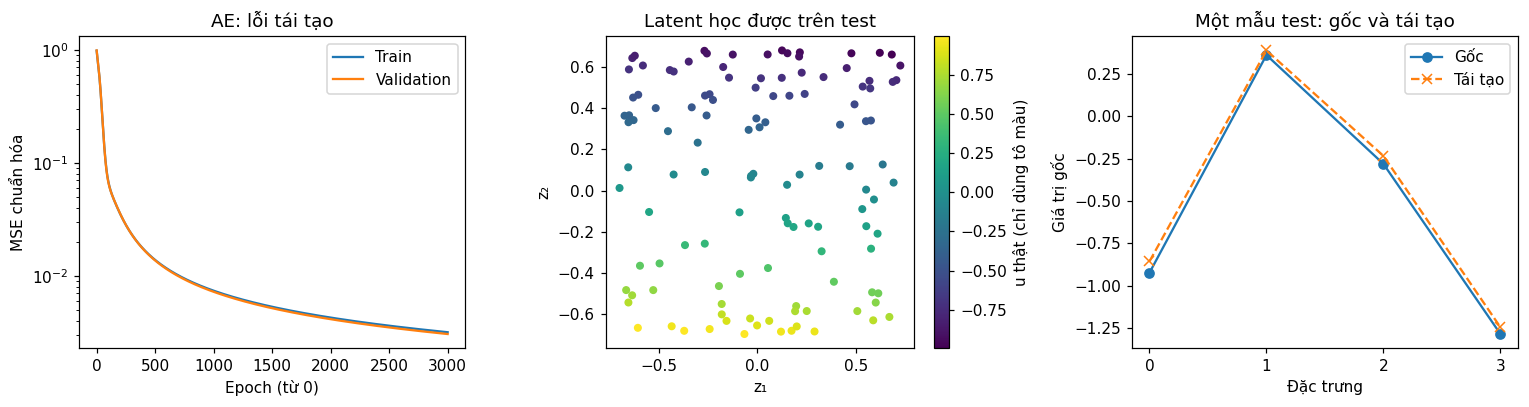

x gốc:        [-0.9229  0.3608 -0.281  -1.2838]
x chuẩn hóa:  [-1.5459  0.5952 -0.6823 -1.5578]
z = encoder:  [-0.2691  0.6788]
x tái tạo:    [-0.8559  0.3882 -0.2339 -1.2441]


In [7]:
latent_test = encode_ae(X_test, ae)
reconstructed_raw = decode_ae(latent_test, ae) * std_train + mean_train
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].semilogy(ae_history["train"], label="Train")
axes[0].semilogy(ae_history["val"], label="Validation")
axes[0].set(title="AE: lỗi tái tạo", xlabel="Epoch (từ 0)", ylabel="MSE chuẩn hóa")
axes[0].legend()
scatter = axes[1].scatter(latent_test[:, 0], latent_test[:, 1],
                          c=uv[test_idx, 0], cmap="viridis", s=18)
axes[1].set(title="Latent học được trên test", xlabel="z₁", ylabel="z₂")
fig.colorbar(scatter, ax=axes[1], label="u thật (chỉ dùng tô màu)")
axes[2].plot(raw[test_idx[0]], "o-", label="Gốc")
axes[2].plot(reconstructed_raw[0], "x--", label="Tái tạo")
axes[2].set(title="Một mẫu test: gốc và tái tạo", xlabel="Đặc trưng", ylabel="Giá trị gốc", xticks=range(4))
axes[2].legend()
plt.tight_layout()
plt.show()

print("x gốc:       ", raw[test_idx[0]])
print("x chuẩn hóa: ", X_test[0])
print("z = encoder: ", latent_test[0])
print("x tái tạo:   ", reconstructed_raw[0])

**Đọc kết quả:** loss thấp hơn baseline cho thấy hai khối đã học giữ và sử dụng thông tin trên dữ liệu tổng hợp này. Latent có thể xoay/đổi tỉ lệ so với `u, v`; mỗi tọa độ không có nhãn ý nghĩa cố định. Không suy ra rằng mọi vector 4D đều nén xuống 2D mà khôi phục chính xác. Với dữ liệu thật, chiều latent, nhiễu, độ phức tạp và regularization đều ảnh hưởng kết quả.

## 3. CBOW: ngữ cảnh → embedding ẩn → từ ở giữa

Ví dụ `học_sinh [đọc] sách`: đầu vào là `học_sinh` và `sách`; mục tiêu là `đọc`. Ngữ cảnh cũng có thể đi với `xem`, nên có những đầu vào có **nhiều từ mục tiêu hợp lý**. Một mô hình xác suất không nên bị yêu cầu đạt accuracy 100% trên bài toán mơ hồ này.

Với từ vựng `V`, chiều embedding `d`, hai từ ngữ cảnh `a, b`:

$$X=\frac{\mathrm{onehot}(a)+\mathrm{onehot}(b)}{2},\quad
H=XW_{in}=\frac{W_{in}[a]+W_{in}[b]}{2},\quad
S=HW_{out}+b_{out},\quad P=\mathrm{softmax}(S).$$

`Win` có shape `(V, d)`; `Wout` có shape `(d, V)`. Hidden là **phép chiếu tuyến tính**, không thêm ReLU/tanh trong ví dụ Word2Vec này. `softmax` mới chuyển logits thành phân phối. Từ có ID gần nhau không tự nhiên có nghĩa gần nhau; quan hệ phải được học từ ngữ cảnh. Lấy trung bình làm CBOW này mất thứ tự hai từ ngữ cảnh.

Ta dùng full softmax vì `V` nhỏ. Word2Vec quy mô lớn có thể dùng hierarchical softmax hoặc negative sampling; notebook không cài những tối ưu đó. Nguồn nền tảng: [Mikolov và cộng sự, 2013](https://arxiv.org/abs/1301.3781).

Để dễ theo dõi, ví dụ CBOW chỉ lấy **vị trí giữa mỗi câu ba token** làm mục tiêu. Khi học Word2Vec đầy đủ, ta thường trượt cửa sổ qua nhiều vị trí trong câu. Ở demo CBOW này, các động từ chỉ xuất hiện làm nhãn nên dòng tương ứng trong `Win` không nhận gradient; không dùng chúng để đánh giá embedding CBOW. Ví dụ Skip-gram phía sau duyệt mọi vị trí.

In [8]:
from itertools import product

# Corpus có cấu trúc tự tạo, không đại diện ngôn ngữ tự nhiên ngoài thực tế.
# Dấu _ gộp các từ nhiều âm tiết; split() ở đây không phải bộ tách từ tiếng Việt tổng quát.
groups = [
    (["học_sinh", "sinh_viên", "giáo_viên"], ["đọc", "xem"], ["sách", "báo", "tài_liệu"]),
    (["mèo", "chó", "hổ"], ["ăn", "thích"], ["cá", "thịt", "thức_ăn"]),
    (["lập_trình_viên", "kỹ_sư", "chuyên_gia"], ["viết", "sửa"], ["mã", "chương_trình", "phần_mềm"]),
]
train_sentences, val_sentences, test_sentences = [], [], []
rng_text = np.random.default_rng(SEED)
for subjects, verbs, objects in groups:
    combinations = [(subjects[i], objects[j]) for i, j in product(range(3), repeat=2)]
    # Tách theo cặp ngữ cảnh: cả hai biến thể động từ luôn ở cùng một tập.
    perm = rng_text.permutation(len(combinations))
    for destination, ids in [(train_sentences, perm[:5]),
                             (val_sentences, perm[5:7]),
                             (test_sentences, perm[7:])]:
        for idx in ids:
            subject, obj = combinations[idx]
            destination.extend([(subject, verb, obj) for verb in verbs])

vocab = sorted({token for sentence in train_sentences for token in sentence})
word_to_id = {word: i for i, word in enumerate(vocab)}
V, EMBED_DIM = len(vocab), 4
for sentence in val_sentences + test_sentences:
    assert all(token in word_to_id for token in sentence), "Có OOV trong dữ liệu đánh giá"
assert set(train_sentences).isdisjoint(val_sentences + test_sentences)
assert set(val_sentences).isdisjoint(test_sentences)

def make_cbow(sentences):
    X, y = [], []
    for left, target, right in sentences:
        row = np.zeros(V)
        row[word_to_id[left]] += 0.5
        row[word_to_id[right]] += 0.5
        X.append(row)
        y.append(word_to_id[target])
    return np.array(X), np.array(y, dtype=int)

cb_train, cb_val, cb_test = map(make_cbow, [train_sentences, val_sentences, test_sentences])
assert cb_train[0].shape == (len(train_sentences), V)
assert np.allclose(cb_train[0].sum(axis=1), 1.0)
print("Số câu train / validation / test:", len(train_sentences), len(val_sentences), len(test_sentences))
print(f"V={V}; d={EMBED_DIM}; cấu trúc {V} → {EMBED_DIM} → {V}")
print("Một mẫu train:", train_sentences[0])
print("Một mẫu test với cặp ngữ cảnh chưa xuất hiện trong train:", test_sentences[0])
print("Từ vựng:", vocab)

Số câu train / validation / test: 30 12 12
V=24; d=4; cấu trúc 24 → 4 → 24
Một mẫu train: ('sinh_viên', 'đọc', 'sách')
Một mẫu test với cặp ngữ cảnh chưa xuất hiện trong train: ('sinh_viên', 'đọc', 'tài_liệu')
Từ vựng: ['báo', 'chuyên_gia', 'chó', 'chương_trình', 'cá', 'giáo_viên', 'học_sinh', 'hổ', 'kỹ_sư', 'lập_trình_viên', 'mã', 'mèo', 'phần_mềm', 'sinh_viên', 'sách', 'sửa', 'thích', 'thịt', 'thức_ăn', 'tài_liệu', 'viết', 'xem', 'ăn', 'đọc']


### 3.1 Cross-entropy và gradient của mạng nông

Với nhãn one-hot `Y` và `B` mẫu:

$$L=-\frac{1}{B}\sum_i\log P_{i,y_i},\qquad G=(P-Y)/B.$$

Ta có `dWout = H.T @ G`, `dbout = G.sum(axis=0)`, `dWin = X.T @ (G @ Wout.T)`. Đây cũng là cơ chế “loss đi qua decoder rồi encoder”. Với softmax, trừ logit lớn nhất trước khi `exp` giúp tránh tràn số; phép trừ này không thay đổi phân phối.

Code dùng cùng một lớp tính toán cho CBOW/Skip-gram vì khác biệt chính nằm ở cách tạo cặp **đầu vào–mục tiêu**. Bias đầu ra được thêm để dễ mô hình hóa tần suất; đây là phiên bản phục vụ học tập.

In [9]:
def init_word_model(seed=SEED):
    rng = np.random.default_rng(seed)
    return {"Win": rng.normal(0, 0.15, (V, EMBED_DIM)),
            "Wout": rng.normal(0, 0.15, (EMBED_DIM, V)), "bout": np.zeros(V)}

def word_forward(X, p):
    hidden = X @ p["Win"]
    scores = hidden @ p["Wout"] + p["bout"]
    shifted = scores - scores.max(axis=1, keepdims=True)
    log_probs = shifted - np.log(np.exp(shifted).sum(axis=1, keepdims=True))
    return hidden, log_probs

def word_loss_grads(X, y, p):
    hidden, log_probs = word_forward(X, p)
    loss = -log_probs[np.arange(len(y)), y].mean()
    G = np.exp(log_probs)
    G[np.arange(len(y)), y] -= 1
    G /= len(y)
    grads = {"Win": X.T @ (G @ p["Wout"].T),
             "Wout": hidden.T @ G, "bout": G.sum(axis=0)}
    return float(loss), grads

def word_loss(data, p):
    X, y = data
    return float(-word_forward(X, p)[1][np.arange(len(y)), y].mean())

def train_word_model(train_data, val_data, seed=SEED, epochs=1800, lr=0.4):
    p = init_word_model(seed)
    history = {"train": [], "val": []}
    best, best_loss, best_epoch = None, float("inf"), None
    for epoch in range(epochs):
        _, grads = word_loss_grads(*train_data, p)
        for name in p:
            p[name] -= lr * grads[name]
        train_loss, val_loss = word_loss(train_data, p), word_loss(val_data, p)
        history["train"].append(train_loss)
        history["val"].append(val_loss)
        if val_loss < best_loss:
            best, best_loss, best_epoch = {k: v.copy() for k, v in p.items()}, val_loss, epoch + 1
    return best, history, best_epoch

word_grad_count, word_grad_error = gradient_check(
    init_word_model(), lambda p: word_loss_grads(cb_train[0][:5], cb_train[1][:5], p))
print(f"Đã kiểm tra {word_grad_count} tham số NLP; sai số lớn nhất = {word_grad_error:.2e}")
cbow, cb_history, cb_best_epoch = train_word_model(cb_train, cb_val)
print("CBOW: epoch được chọn bằng validation:", cb_best_epoch)

Đã kiểm tra 216 tham số NLP; sai số lớn nhất = 4.97e-10
CBOW: epoch được chọn bằng validation: 1800


In [10]:
def report_word_model(name, train_data, test_data, p):
    X, y = test_data
    probabilities = np.exp(word_forward(X, p)[1])
    assert np.allclose(probabilities.sum(axis=1), 1)
    assert np.isfinite(probabilities).all()
    # Baseline unigram được fit trên nhãn train, làm trơn cộng 1.
    counts = np.bincount(train_data[1], minlength=V) + 1.0
    unigram = counts / counts.sum()
    ce = word_loss(test_data, p)
    baseline_ce = float(-np.log(unigram[y]).mean())
    accuracy = float((probabilities.argmax(axis=1) == y).mean())
    print(f"{name} | Test cross-entropy: {ce:.4f} | Unigram baseline: {baseline_ce:.4f}")
    print(f"{name} | Test top-1 accuracy: {accuracy:.1%}")
    return {"ce": ce, "baseline_ce": baseline_ce, "accuracy": accuracy}

cb_metrics = report_word_model("CBOW", cb_train, cb_test, cbow)
assert cb_metrics["ce"] < cb_metrics["baseline_ce"]

def show_cbow(left, right, k=5):
    missing = [w for w in (left, right) if w not in word_to_id]
    if missing:
        raise ValueError(f"Từ ngoài từ vựng: {missing}. Demo chưa có cơ chế <UNK>.")
    x = np.zeros((1, V))
    x[0, word_to_id[left]] += 0.5
    x[0, word_to_id[right]] += 0.5
    hidden, log_probs = word_forward(x, cbow)
    ranking = np.argsort(-log_probs[0])[:k]
    print(f"\nNgữ cảnh: {left} [ ? ] {right}")
    print("Hidden z:", hidden[0])
    for idx in ranking:
        print(f"  {vocab[idx]:18s} {np.exp(log_probs[0, idx]):.3f}")
    return x, hidden

left, _, right = test_sentences[0]
sample_cbow_x, sample_cbow_h = show_cbow(left, right)
# X @ Win chính là trung bình hai dòng embedding được tra cứu bằng ID.
lookup_mean = (cbow["Win"][word_to_id[left]] + cbow["Win"][word_to_id[right]]) / 2
assert np.allclose(sample_cbow_h[0], lookup_mean)

CBOW | Test cross-entropy: 0.7008 | Unigram baseline: 2.1972
CBOW | Test top-1 accuracy: 50.0%

Ngữ cảnh: sinh_viên [ ? ] tài_liệu
Hidden z: [-1.3753  0.0749 -0.1636  0.8215]
  đọc                0.505
  xem                0.493
  sửa                0.000
  viết               0.000
  thích              0.000


**Tại sao accuracy CBOW có thể chỉ quanh 50% dù loss tốt?** Với mỗi cặp chủ ngữ–tân ngữ, corpus chứa hai động từ cân bằng. Input giống hệt nhưng có hai nhãn hợp lệ. Nếu mô hình chia xác suất gần 0.5–0.5, cross-entropy tốt nhất cho cặp đó gần `ln(2) ≈ 0.693`, còn chọn một từ bằng argmax chỉ đúng một trong hai câu. Đây là sự mơ hồ do thiết kế dữ liệu, không phải lỗi backprop.

Tập test giữ lại những **cặp ngữ cảnh** không có trong train nhưng vẫn dùng từ vựng đã biết. Kết quả chỉ kiểm tra khái quát tổ hợp trong corpus tổng hợp nhỏ này, không đo năng lực hiểu tiếng Việt ngoài đời. Muốn thử cặp khác, gọi `show_cbow("học_sinh", "sách")`; cặp ấy có thể thuộc train nên phải ghi đúng tính chất khi trình bày.

## 4. Skip-gram: từ giữa → embedding → từ ngữ cảnh

CBOW gộp nhiều từ để đoán một từ. Skip-gram dùng một từ giữa để dự đoán các từ trong cửa sổ ngữ cảnh. Với câu `học_sinh đọc sách`, cửa sổ bán kính 1 tạo các cặp:

```text
(học_sinh → đọc), (đọc → học_sinh), (đọc → sách), (sách → đọc)
```

Mỗi cặp là một mục tiêu softmax riêng. Một từ giữa thường có nhiều hàng mục tiêu khác nhau, vì vậy output là phân phối nhiều khả năng, không phải một “câu giải mã”. Ở đầu/cuối câu, cửa sổ có ít hàng hơn; ví dụ này cho mỗi cặp trọng số như nhau.

Ta giữ nguyên `Win`, `Wout`, softmax, cross-entropy và backprop đã viết. Chỉ thay `X` từ trung bình one-hot thành one-hot của từ giữa, và `y` thành ID một từ ngữ cảnh.

In [11]:
def make_skipgram(sentences, radius=1):
    X, y = [], []
    for sentence in sentences:
        ids = [word_to_id[word] for word in sentence]
        for i, center in enumerate(ids):
            for j in range(max(0, i - radius), min(len(ids), i + radius + 1)):
                if i == j:
                    continue
                row = np.zeros(V)
                row[center] = 1.0
                X.append(row)
                y.append(ids[j])
    return np.array(X), np.array(y, dtype=int)

sg_train, sg_val, sg_test = map(make_skipgram, [train_sentences, val_sentences, test_sentences])

def unique_pairs(data):
    return set(zip(data[0].argmax(axis=1).tolist(), data[1].tolist()))

pair_overlap = len(unique_pairs(sg_train) & unique_pairs(sg_test))
print("Số cặp train / validation / test:", *(len(d[1]) for d in [sg_train, sg_val, sg_test]))
print(f"Cặp (từ giữa, ngữ cảnh) test trùng train: {pair_overlap}/{len(unique_pairs(sg_test))}")

skipgram, sg_history, sg_best_epoch = train_word_model(sg_train, sg_val, seed=SEED + 1)
print("Skip-gram: epoch chọn bằng validation:", sg_best_epoch)
sg_metrics = report_word_model("Skip-gram", sg_train, sg_test, skipgram)
assert sg_metrics["ce"] < sg_metrics["baseline_ce"]

Số cặp train / validation / test: 120 48 48
Cặp (từ giữa, ngữ cảnh) test trùng train: 36/36
Skip-gram: epoch chọn bằng validation: 1800
Skip-gram | Test cross-entropy: 1.4443 | Unigram baseline: 3.1790
Skip-gram | Test top-1 accuracy: 27.1%


**Giới hạn phép chia Skip-gram:** các câu test khác câu train, nhưng cặp hai từ có thể trùng giữa hai tập. Cell trên báo số trùng một cách trực tiếp. Do đó test Skip-gram ở đây là kiểm tra dự đoán ngữ cảnh trên câu giữ lại, **không phải bài kiểm tra các cặp từ hoàn toàn mới**. Không dùng accuracy của demo này để tuyên bố chất lượng embedding thực tế.

### 4.1 Xem output decoder và dùng encoder độc lập

Phân phối `softmax(z @ Wout + bout)` cho biết từ ngữ cảnh được dự đoán. Còn tìm từ gần nhau bằng cosine giữa các dòng `Win` là một cách **sử dụng embedding sau khi học**, không phải cùng phép toán với decoder.

In [12]:
def inspect_skipgram(center="đọc", k=5):
    if center not in word_to_id:
        raise ValueError(f"Từ ngoài từ vựng: {center}")
    idx = word_to_id[center]
    one_hot = np.eye(V)[idx:idx + 1]
    hidden, log_probs = word_forward(one_hot, skipgram)
    assert np.allclose(hidden[0], skipgram["Win"][idx])
    print("Từ giữa:", center, "| Embedding:", hidden[0])
    print("Decoder dự đoán các từ ngữ cảnh:")
    for j in np.argsort(-log_probs[0])[:k]:
        print(f"  {vocab[j]:18s} {np.exp(log_probs[0, j]):.3f}")

    normalized = skipgram["Win"] / np.maximum(np.linalg.norm(skipgram["Win"], axis=1, keepdims=True), 1e-12)
    similarity = normalized @ normalized[idx]
    similarity[idx] = -np.inf
    print("Các từ gần theo cosine của embedding đầu vào:")
    for j in np.argsort(-similarity)[:k]:
        print(f"  {vocab[j]:18s} {similarity[j]:.3f}")

inspect_skipgram()

Từ giữa: đọc | Embedding: [2.0018 1.1479 2.1064 1.3532]
Decoder dự đoán các từ ngữ cảnh:
  báo                0.200
  sinh_viên          0.200
  học_sinh           0.199
  sách               0.199
  giáo_viên          0.100
Các từ gần theo cosine của embedding đầu vào:
  xem                1.000
  viết               0.127
  sửa                0.124
  thịt               0.118
  thức_ăn            0.096


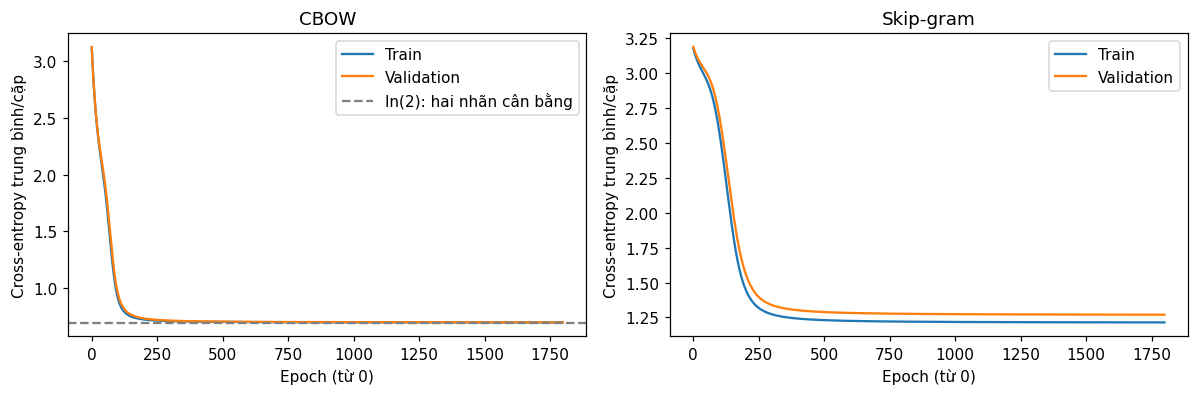

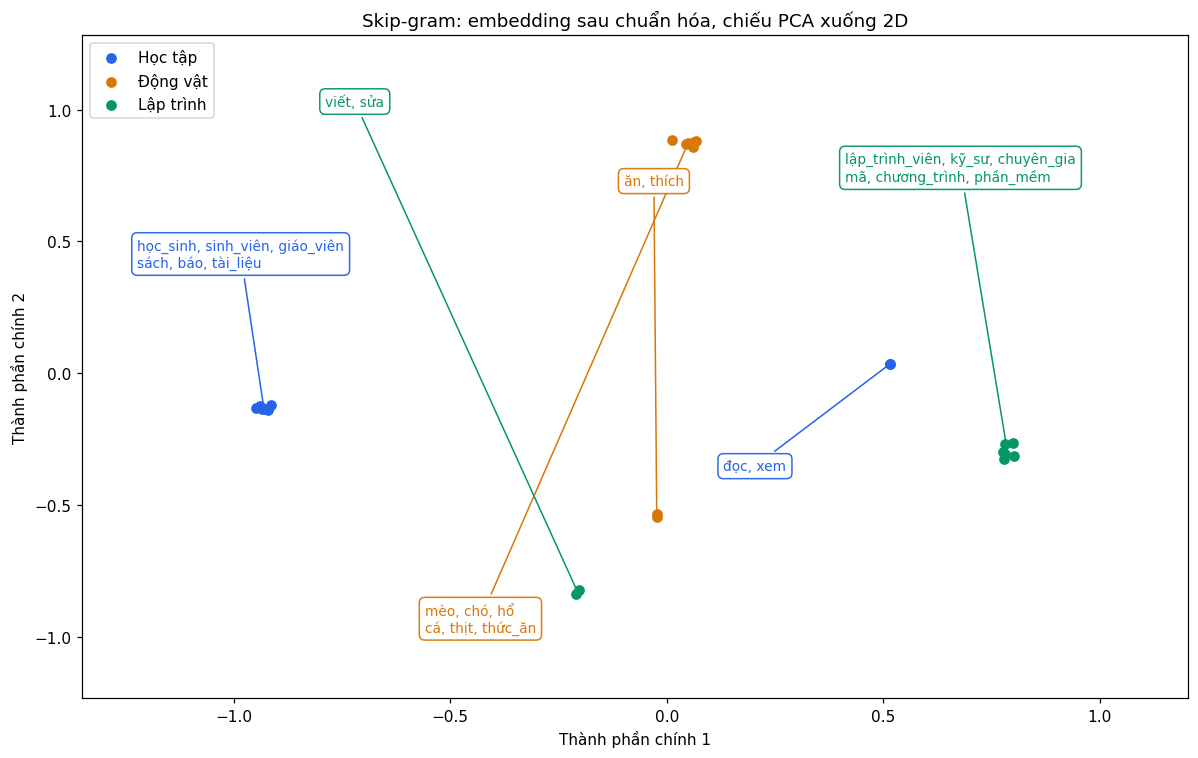

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
for ax, name, history in [(axes[0], "CBOW", cb_history), (axes[1], "Skip-gram", sg_history)]:
    ax.plot(history["train"], label="Train")
    ax.plot(history["val"], label="Validation")
    ax.set(title=name, xlabel="Epoch (từ 0)", ylabel="Cross-entropy trung bình/cặp")
    ax.legend()
axes[0].axhline(np.log(2), color="gray", ls="--", label="ln(2): hai nhãn cân bằng")
axes[0].legend()
plt.tight_layout()
plt.show()

# Chuẩn hóa rồi PCA về 2D chỉ để vẽ; không huấn luyện lại model.
embedding = skipgram["Win"]
normalized = embedding / np.maximum(np.linalg.norm(embedding, axis=1, keepdims=True), 1e-12)
centered = normalized - normalized.mean(axis=0)
_, _, vt = np.linalg.svd(centered, full_matrices=False)
xy = centered @ vt[:2].T
fig, ax = plt.subplots(figsize=(11, 7))
colors = ["#2563eb", "#d97706", "#059669"]
# Các điểm có ngữ cảnh giống nhau nằm rất gần; dùng nhãn nhóm nối tới tâm
# để đọc được chữ. Không dịch chuyển các điểm dữ liệu để làm đẹp hình.
label_positions = [((0.05, 0.67), (0.58, 0.35)),
                   ((0.31, 0.12), (0.49, 0.78)),
                   ((0.69, 0.80), (0.22, 0.90))]
for group, color, label, positions in zip(groups, colors, ["Học tập", "Động vật", "Lập trình"], label_positions):
    ids = [word_to_id[w] for part in group for w in part]
    ax.scatter(xy[ids, 0], xy[ids, 1], color=color, s=36, label=label)
    nouns, verbs = group[0] + group[2], group[1]
    for words, label_position in zip([nouns, verbs], positions):
        point = xy[[word_to_id[w] for w in words]].mean(axis=0)
        text = ", ".join(words[:3]) + ("\n" + ", ".join(words[3:]) if len(words) > 3 else "")
        ax.annotate(text, point, xytext=label_position, textcoords="axes fraction",
                    fontsize=9, color=color, va="center",
                    bbox={"boxstyle": "round,pad=0.4", "fc": "white", "ec": color, "alpha": 0.95},
                    arrowprops={"arrowstyle": "-", "color": color, "lw": 1})
ax.set(title="Skip-gram: embedding sau chuẩn hóa, chiếu PCA xuống 2D",
       xlabel="Thành phần chính 1", ylabel="Thành phần chính 2")
ax.margins(0.23)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

**Đọc hình embedding:** màu nhóm do người viết gán để quan sát, không đưa vào loss. Những từ có ngữ cảnh tương tự có thể được đặt gần nhau. Corpus nhỏ, không gian 4D và phép chiếu PCA có thể gây chồng điểm hoặc khoảng cách khó diễn giải. Hình 2D và một vài từ láng giềng chỉ là minh họa, không đủ để kết luận mô hình học được “ngữ nghĩa tiếng Việt”.

Không so sánh trực tiếp trị số loss CBOW với Skip-gram để kết luận kiến trúc nào tốt hơn: tập cặp, nhãn và độ bất định khác nhau. Các mô hình này cũng chưa xử lý OOV bằng subword, biến thể dấu, thứ tự câu hay nghĩa phụ thuộc ngữ cảnh như mô hình hiện đại.

## 5. Kết quả chạy và những điều cần nhớ

Cell dưới tạo bảng từ biến của lần chạy hiện tại. Test chỉ dùng để báo cáo/kiểm tra sau khi chọn checkpoint bằng validation; không dùng để chọn epoch tốt nhất.

In [14]:
display(Markdown(
    "| Mô hình | Kiến trúc | Test loss | Baseline test loss |\n"
    "|---|---|---:|---:|\n"
    f"| Autoencoder | 4 → 2 → 4 | MSE {test_ae_loss:.6f} | Mean: {mean_baseline_mse:.6f} |\n"
    f"| CBOW | {V} → {EMBED_DIM} → {V} | CE {cb_metrics['ce']:.4f} | Unigram: {cb_metrics['baseline_ce']:.4f} |\n"
    f"| Skip-gram | {V} → {EMBED_DIM} → {V} | CE {sg_metrics['ce']:.4f} | Unigram: {sg_metrics['baseline_ce']:.4f} |"
))
print("Kiểm tra hoàn tất: gradient AE/NLP, split, shape, xác suất, loss hữu hạn và baseline.")

| Mô hình | Kiến trúc | Test loss | Baseline test loss |
|---|---|---:|---:|
| Autoencoder | 4 → 2 → 4 | MSE 0.003251 | Mean: 1.046225 |
| CBOW | 24 → 4 → 24 | CE 0.7008 | Unigram: 2.1972 |
| Skip-gram | 24 → 4 → 24 | CE 1.4443 | Unigram: 3.1790 |

Kiểm tra hoàn tất: gradient AE/NLP, split, shape, xác suất, loss hữu hạn và baseline.


### 5.1 Tự giải thích lại mà không nhìn code

1. **Tham số nào thuộc encoder, tham số nào thuộc decoder?** AE: `We, be` và `Wd, bd`; Word2Vec demo: `Win` và `Wout, bout`.
2. **Latent có phải là nhãn?** Không. Latent được học sao cho loss của nhiệm vụ giảm; không có bảo đảm mỗi chiều là một khái niệm dễ gọi tên.
3. **Vì sao loss của decoder cập nhật được encoder?** Vì output phụ thuộc latent và latent phụ thuộc tham số encoder; gradient truyền qua chuỗi phụ thuộc đó.
4. **Autoencoder khác CBOW ở đâu?** Autoencoder đặt mục tiêu bằng dữ liệu cần tái tạo; CBOW đặt mục tiêu là từ ở giữa, thường không nằm trong input context.
5. **Vì sao ID → embedding chưa phải toàn bộ encoder–decoder?** Đó mới là tra cứu biểu diễn. Cần xác định đầu ra, khối dự đoán và loss học tham số.
6. **Tại sao seq2seq cần BOS/EOS/PAD?** BOS bắt đầu decoder; EOS kết thúc chuỗi; PAD làm đều batch và phải được bỏ khỏi loss/attention phù hợp.
7. **Teacher forcing có áp dụng cho CBOW này không?** Không. CBOW dự đoán một token độc lập từ context, không chạy chuỗi decoder tự hồi quy.
8. **Có thể dùng decoder autoencoder để sinh dữ liệu bất kỳ không?** Có thể đưa `z` vào decoder, nhưng điểm latent xa vùng đã học có thể cho đầu ra vô nghĩa. Autoencoder thường không học phân phối latent như VAE.

### 5.2 Các thử nghiệm tự làm tiếp

- Đổi latent AE thành 1 hoặc 3 chiều, sửa kích thước tham số và quan sát sai số. Hai chiều phù hợp cấu trúc dữ liệu hiện tại nhưng không phải lựa chọn mặc định cho mọi bài toán.
- Thay đổi số chiều embedding, giữ nguyên split và seed. So sánh trên validation; dành test cho lần đánh giá cuối.
- Thêm câu thuộc nhiều chủ đề và quan sát từ đa nghĩa. Nhãn nhóm chỉ dùng vẽ, không dùng huấn luyện.
- Thay full softmax bằng negative sampling là một bước học tiếp; cần thay cả loss và gradient, không chỉ lấy ngẫu nhiên vài phần tử softmax.

Ba ý quan trọng: **xác định input–target trước; theo dõi biểu diễn và shape; giải thích gradient đi qua cả encoder và decoder**. Khi ba phần này rõ, chuyển sang GRU hoặc Transformer sẽ dễ hiểu hơn việc chỉ gọi một model có sẵn.

### 5.3 Liên hệ với đề tài và tài liệu đọc

Xem [ba đề tài đã chọn](03_de_tai_NCKHSV.md). Tóm tắt tiếng Việt dùng encoder–decoder sinh chuỗi; RAG là kiến trúc hệ thống có retriever và generator; tra cứu ảnh thường chỉ cần encoder. Các ví dụ nhỏ trong notebook này không phải code của ba đề tài.

- Tài liệu môn học: [NLP-1.pdf](slide/NLP-1.pdf), trang 6–16.
- Mikolov và cộng sự, [Efficient Estimation of Word Representations in Vector Space](https://arxiv.org/abs/1301.3781), 2013: CBOW và Skip-gram.
- Sutskever và cộng sự, [Sequence to Sequence Learning with Neural Networks](https://arxiv.org/abs/1409.3215), 2014: mô hình chuỗi đầu vào–đầu ra.
- Bahdanau và cộng sự, [Neural Machine Translation by Jointly Learning to Align and Translate](https://arxiv.org/abs/1409.0473), bản thảo 2014, ICLR 2015: attention cho dịch máy.
- Vaswani và cộng sự, [Attention Is All You Need](https://arxiv.org/abs/1706.03762), 2017: Transformer encoder–decoder.
- [ViT5 — mã nguồn chính thức](https://github.com/vietai/ViT5): liên hệ từ kiến thức nền đến sinh văn bản tiếng Việt.

Biên soạn và đối chiếu tài liệu ngày 08/10/2026. Toàn bộ số liệu thực nghiệm trong notebook thuộc dữ liệu minh họa tự tạo, không phải kết quả từ các bài báo hay từ dữ liệu người dùng.